# 1. Getting Kar et al. (2019) data

First, the data about alexnet performance, human performance, images and their categories are appended in arrays

In [ ]:
# importing the human data of Kar et al. (2019)

from ast import Not
import numpy as np
import matplotlib.pyplot as plt
import h5py
from google.colab import drive

# get data, which is already uploaded into google drive
drive.mount('/content/gdrive')
h5path = '/content/gdrive/MyDrive/human_data_1320-1.h5'
data = h5py.File(h5path, 'r')
hd2 = np.array(data['i1'])[0]

# add all data except the natural images (photographs) to a list
human_d2 = []
for i in range (1320):
  # exlude natural images by means of their index in the dataset array
  if not (80 <= i < 100 or 212 <= i < 232 or 344 <= i < 364 or 476 <= i < 496 or 608 <= i < 628 or 740 <= i < 760 or 872 <= i < 892 or 1004 <= i < 1024 or 1136 <= i < 1156 or 1268 <= i < 1288):
    human_d2.append(hd2[i])

Mounted at /content/gdrive


In [ ]:
# Original Alexnet of paper, USE THIS ONE

# Get data from google drive
drive.mount('/content/gdrive')
h5path2 = '/content/gdrive/MyDrive/nn_data.h5'
data2 = h5py.File(h5path2, 'r')
alexnet_paper_d2 = np.array(data2['alexnet_1320'][0])

# add data to array, except natural stimuli again
alex_d2 = []
for i in range(1320):
  if not (80 <= i < 100 or 212 <= i < 232 or 344 <= i < 364 or 476 <= i < 496 or 608 <= i < 628 or 740 <= i < 760 or 872 <= i < 892 or 1004 <= i < 1024 or 1136 <= i < 1156 or 1268 <= i < 1288):
    alex_d2.append(alexnet_paper_d2[i])
print(len(alex_d2))
print(alex_d2)

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).
1120
[1.7918072904880344, 2.089050854947074, 1.8929868302680994, 2.9373612060841254, 3.080682922984814, 2.861942443756469, 1.7070637924886598, 3.233356586950446, 3.295757122836071, 1.648721258735626, 1.4247286837996178, 3.4766683548108617, 3.323338206270962, 3.4070759650676994, 1.9158409559799576, 2.1507051902452248, 2.5668630404609862, 1.9137055827260259, 1.2972412206708444, 2.0513824171588815, 2.4327332952112775, 2.2291867330453976, 1.9209429545916734, 1.7160432377657937, 2.2060363455734677, 2.990434202935883, 2.616114681679515, 1.5902845554764293, 2.3660255396949617, 2.7904629592050494, 0.10282724267800435, 1.472068351052565, 2.506915105274385, 1.911817327037848, 2.7736748473967343, 2.083967938075841, 3.2818623105475395, 3.1232496186811685, 3.0602817955819304, 3.0295440447128286, 2.586199770016628, 1.4958539231786885, 2.2302790783311535, 1.52646544333250

In [ ]:
# Updated 2021 Alexnet, DO NOT USE, code included just in case

# drive.mount('/content/gdrive')
# h5path3 = '/content/gdrive/MyDrive/model_dp-2.h5'
# data3 = h5py.File(h5path2, 'r')
# d3 = np.array(data2['i1'])[0]
# alex_2021_d2 = []
# for i in range (1320):
 # if not (80 <= i < 100 or 212 <= i < 232 or 344 <= i < 364 or 476 <= i < 496 or 608 <= i < 628 or 740 <= i < 760 or 872 <= i < 892 or 1004 <= i < 1024 or 1136 <= i < 1156 or 1268 <= i < 1288):
    # alex__2021_d2.append(d2[i])
# print(len(alex_2021_d2))
# print(alex__2021_d2)

In [ ]:
# get stimuli and corresponding object as well as monkey performance data

# load data from google drive
h5path4 = '/content/gdrive/MyDrive/dataset.h5'
data4 = h5py.File(h5path4, 'r')
img_data = np.array(data4['images'])
obj_data = np.array(data4['obj'])[0] # object displayed in images, corresponding indexes
i1_data = np.array(data4['i1'])[0]  # monkey behavioral performance

# add all stimuli except the natural ones to array
img = []
obj = []
i1 = []
for i in range (1320):
  if not (80 <= i < 100 or 212 <= i < 232 or 344 <= i < 364 or 476 <= i < 496 or 608 <= i < 628 or 740 <= i < 760 or 872 <= i < 892 or 1004 <= i < 1024 or 1136 <= i < 1156 or 1268 <= i < 1288):
    img.append(img_data[i])
    obj.append(obj_data[i])
    i1.append(i1_data[i])

In [ ]:
import numpy as np
from scipy import stats
i1_array = np.array(i1)
hd2_array = np.array(hd2)
print(f"monkey performance: M = {i1_array.mean()}, std = {i1_array.std()}")
print(f"human performance: M = {hd2_array.mean()}, std = {hd2_array.std()}")
stats.ttest_ind(i1_array, hd2_array)

monkey performance: M = 2.7115258551023764, std = 0.5582144271771396
human performance: M = 3.2233491388515167, std = 0.9800792020252782


Ttest_indResult(statistic=-15.470078686030181, pvalue=1.4378723644387565e-51)

# 2. Defining the control and challenge images
The control and challence images are defined. Challenge images can be solved by humans but not alexnet, control images can be solved by both.

Note: The control images are now defined as images that can actually be solved by both. Images that are unsolvable have been filtered out.

Note: also the images with only visual information on the right half are filtered out for a more homogeneous stimuli set.

In [ ]:
# append all images, their corresponding objects, and their corresponding performance data (monkey, human and alex data) into arrays for challenge and control conditions

# create arrays for data for challenge and control condition, all indexes of the different lists correspond and refer to the same stimulus
human_d2_chal = []  #human performance data
human_d2_con = []
human_rest = []
alex_d2_chal = []  # alexnet performance data
alex_d2_con = []
alex_rest = []
obj_chal = [] # objects corresponding to images
obj_con = []
obj_rest = []
img_con = [] # image  data
img_chal = []
img_rest = []
i1_chal = []  # monkey performance data
i1_con = []

# add images that satisfy conditions based on Kar et al., 2019 for either challenge, control or else rest images to arrays
for i in range(1120):
  image = np.transpose(img[i], (2,1,0))  # immediately transform image data to printable format

  # if the performance of humans is close to alexnet performance, the image is a control image, based on Kar et al. (2019)
  # also, exclude human performance outliers, images displaying distorted objects, and images only displaying half of the object
  if (abs(human_d2[i] - alex_d2[i])) < 1 and (human_d2[i] < 4) and (human_d2[i] > 2.09) and not (np.mean(image[50:100,50:100,:]) == 127):
    human_d2_con.append(human_d2[i])
    alex_d2_con.append(alex_d2[i])
    obj_con.append(obj[i])
    img_con.append(img[i])
    i1_con.append(i1[i])

  # if the human performance is significantly larger than alex performance, image is challenge images, also similar exclusion criteria as the control images
  elif (human_d2[i] - alex_d2[i]) > 1.6 and (human_d2[i] < 4) and (human_d2[i] > 2.09) and not (np.mean(image[50:100,50:100,:]) == 127):
    human_d2_chal.append(human_d2[i])
    alex_d2_chal.append(alex_d2[i])
    obj_chal.append(obj[i])
    img_chal.append(img[i])
    i1_chal.append(i1[i])

  # images that do not satisfy previous conditions are rest images, but as those are also needed same exclusion criteria apply
  elif not (np.mean(image[50:100,50:100,:]) == 127) and (human_d2[i] < 4) and (human_d2[i] > 2.09):
    human_rest.append(human_d2[i])
    alex_rest.append(alex_d2[i])
    obj_rest.append(obj[i])
    img_rest.append(img[i])


# lists are transformed into arrays, as arrays are needed later on
int_obj_chal = [int(x) for x in obj_chal]
array_obj_chal = np.array(int_obj_chal)
array_alex_d2_chal = np.array(alex_d2_chal)
array_human_d2_chal = np.array(human_d2_chal)
int_obj_con = [int(x) for x in obj_con]
array_obj_con = np.array(int_obj_con)
array_alex_d2_con = np.array(alex_d2_con)
array_human_d2_con = np.array(human_d2_con)
array_i1_con = np.array(i1_con)
array_i1_chal = np.array(i1_chal)
array_human_rest = np.array(human_rest)
array_alex_rest = np.array(alex_rest)

In [ ]:
print(f"challenge:")
print(f"monkey: M = {array_i1_chal.mean()}, std = {array_i1_chal.std()}")
print(f"human: M = {array_human_d2_chal.mean()}, std = {array_human_d2_chal.std()}")
print(f"control:")
print(f"monkey: M = {array_i1_con.mean()}, std = {array_i1_con.std()}")
print(f"human: M = {array_human_d2_con.mean()}, std = {array_human_d2_con.std()}")

print("t-tests:")
stats.ttest_ind(array_i1_chal, array_i1_con, equal_var=False)
#print("t-test control")
#stats.ttest_ind(array_i1_con, array_human_d2_con)

challenge:
monkey: M = 2.7267095363236984, std = 0.5222754519497372
human: M = 3.1982302689304656, std = 0.389670441208677
control:
monkey: M = 2.775771753261823, std = 0.5404833833888076
human: M = 2.9379908814706384, std = 0.4916148130045699
t-tests:


Ttest_indResult(statistic=-1.035969965644082, pvalue=0.3007233754731856)

# Test for correct challenge control assignment

Looking at the data the challenge and control images may have been swapped, following code prints images from categories with few amounts of images. These will certainly make the final sample so that is why they are examined. One example for challenge and one example for control condition

In [ ]:
# control dog category with only 9 images total, so 8 of these should be in the final control sample
for i in range(99,108):
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_con[i], (2,1,0)))/255)
# if needed, the corresponding human performance can be printed as well
  plt.xlabel(human_d2_con[i])

In [ ]:
# same for the challenge zebra category, only 10 images of which 8 should make it into the final sample so this is a good test
for i in range(262,270):
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_chal[i], (2,1,0)))/255)
# again, if needed the performance can be printed
  plt.xlabel(human_d2_chal[i])

In [ ]:
# if needed, the total performance for monkeys and humans can be printed
print(f"total CHALLENGE human d' = {np.mean(array_human_d2_chal)}, monkey d' = {np.mean(array_i1_chal)}")
print(f"total CONTROL human d' = {np.mean(array_human_d2_con)}, monkey d' = {np.mean(array_i1_con)}")

total CHALLENGE human d' = 3.1982302689304656, monkey d' = 2.7267095363236984
total CONTROL human d' = 2.9379908814706384, monkey d' = 2.775771753261823


# Visualizing the control and challenge images in a scatterplot similar to the scatterplot in the paper

1. Scatterplot with red and blue colors for the wstimulus difficulty, see figure 1B in Kar et al (2019)

2. Scatterplot with different colors corresponding to the different categories

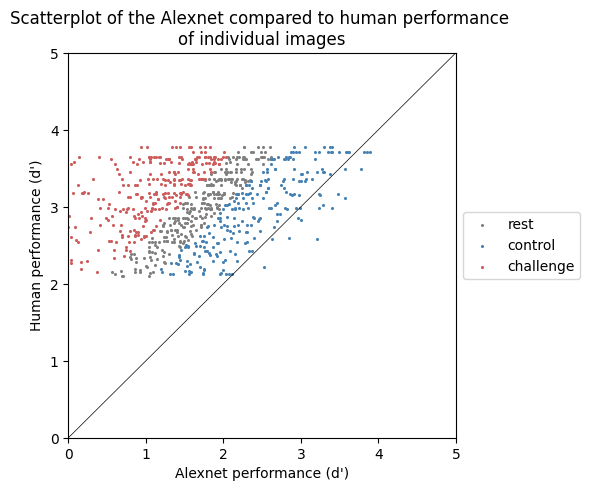

In [ ]:
import numpy as np

# scatterplot visualizing blue control, vs red challenge, vs grey control images

from collections import Counter
fig = plt.figure(figsize=(5,5))
ax1 = fig.add_subplot(111)
plt.xlim([0,5])
plt.ylim([0,5])
ax1.scatter(alex_rest, human_rest, s=1.5, c='grey', marker="o", label='rest')
ax1.scatter(alex_d2_con, human_d2_con, s=1.5, c='steelblue', marker="o", label='control')
ax1.scatter(alex_d2_chal, human_d2_chal, s=1.5, c='indianred', marker="o", label='challenge')
plt.legend(loc='center left', bbox_to_anchor=(1, 0.5), fancybox=True)
x = [0,5]
y = [0,5]
plt.plot(x,y, color='black', lw=0.5)
plt.xlabel ("Alexnet performance (d')")
plt.ylabel ("Human performance (d')")
plt.title("Scatterplot of the Alexnet compared to human performance \nof individual images")
plt.show()

np.savetxt("alex_chal.csv", array_alex_d2_chal , delimiter=",")
np.savetxt("human_chal.csv", array_human_d2_chal , delimiter=",")
np.savetxt("alex_con.csv", array_alex_d2_con , delimiter=",")
np.savetxt("human_con.csv", array_human_d2_con , delimiter=",")
np.savetxt("alex_rest.csv", array_alex_rest , delimiter=",")
np.savetxt("human_rest.csv", array_human_rest , delimiter=",")

there are 24 CHALLENGE images for category bear
there are 31 CONTROL images for category bear
there are 40 CHALLENGE images for category elph
there are 21 CONTROL images for category elph
there are 26 CHALLENGE images for category face
there are 29 CONTROL images for category face
there are 38 CHALLENGE images for category car
there are 18 CONTROL images for category car
there are 40 CHALLENGE images for category dog
there are 10 CONTROL images for category dog
there are 14 CHALLENGE images for category apple
there are 30 CONTROL images for category apple
there are 30 CHALLENGE images for category chair
there are 18 CONTROL images for category chair
there are 31 CHALLENGE images for category plane
there are 13 CONTROL images for category plane
there are 19 CHALLENGE images for category bird
there are 26 CONTROL images for category bird
there are 9 CHALLENGE images for category zebra
there are 42 CONTROL images for category zebra


Text(0, 0.5, 'human d2')

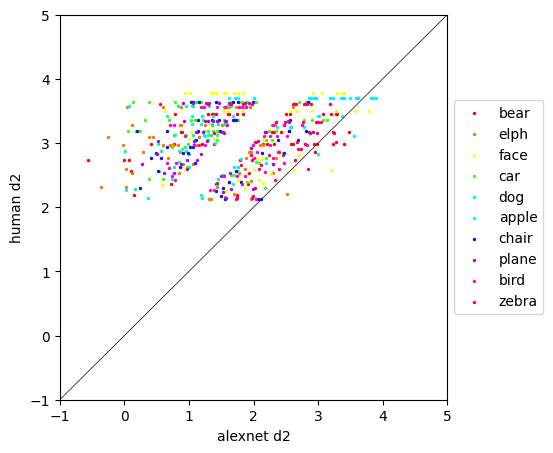

In [ ]:
# plot with different colors per category, to get a rough idea of the performance per category

# set one color per catgeory
color = ['#FF0202','#FF7500','#FEFF05','#43FB05','#00FF9B','#00EFFF','#060EFB','#AA00FF','#FF00D4','#FF0059']
label = ['bear', 'elph', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']

fig = plt.figure(figsize=(5,5))
ax1 = fig.add_subplot(111)
plt.xlim([-1,5])
plt.ylim([-1,5])

# plot dots per category
for i in range(1,11):
  obj_idx_chal = array_obj_chal == i
  ax1.scatter(array_alex_d2_chal[obj_idx_chal], array_human_d2_chal[obj_idx_chal], s=2, c=color[i-1],marker="o", label=label[i-1])

# if needed, the amount of images per category can be printed as well
  print(f"there are {len(array_alex_d2_chal[obj_idx_chal])} CHALLENGE images for category {label[i-1]}")

# if needed, the average performance per category can be printed as well
  # print(f"CHALLENGE {label[i-1]}: HUMAN: {np.mean(array_human_d2_chal[obj_idx_chal])}, MONKEY: {np.mean(array_i1_chal[obj_idx_chal])}, ALEX: {np.mean(array_alex_d2_chal[obj_idx_chal])}")
  # print(f"the MONKEY d2 mean for CHALLENGE {label[i-1]} is {np.mean(array_i1_chal[obj_idx_chal])}")
  # print(f"the ALEX d2 mean for CHALLENGE {label[i-1]} is {np.mean(array_alex_d2_chal[obj_idx_chal])}")

  obj_idx_con = array_obj_con == i
  ax1.scatter(array_alex_d2_con[obj_idx_con], array_human_d2_con[obj_idx_con], s=2, c=color[i-1],marker="o")

  print(f"there are {len(array_alex_d2_con[obj_idx_con])} CONTROL images for category {label[i-1]}")

  # print(f"CONTROL {label[i-1]}: HUMAN: {np.mean(array_human_d2_con[obj_idx_con])}, MONKEY: {np.mean(array_i1_con[obj_idx_con])}, ALEX: {np.mean(array_alex_d2_con[obj_idx_con])}")
  # print(f"the MONKEY d2 mean for CONTROL {label[i-1]} is {np.mean(array_i1_con[obj_idx_con])}")
  # print(f"the ALEX d2 mean for CONTROL {label[i-1]} is {np.mean(array_alex_d2_con[obj_idx_con])}")

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
plt.plot([-1,5], [-1,5],color='black', linewidth=0.5)
plt.xlabel('alexnet d2')
plt.ylabel('human d2')

# Processing and sampling of rest images to use as distractors

In [ ]:
import numpy as np
import pandas as pd
import random

label = ['bear', 'elph', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']
lookup_random1 = np.empty(80, dtype=object)
c = 0
nr = 700
for i in range(10):
  for j in range(8):
    lookup_random1[c] = [nr, label[i]]
    nr += 1
    c += 1
#random.shuffle(lookup_random1)
print(lookup_random1)

randomization1_1_df = pd.DataFrame(lookup_random1)
randomization1_1_df.to_csv(f'randomization5_df.csv', index=False)
files.download(f'randomization5_df.csv')

In [ ]:
array_alex_rest = np.array(alex_rest)
array_human_rest = np.array(human_rest)
array_obj_rest = np.array(obj_rest)
array_img_rest = np.array(img_rest)
groups_rest = np.empty(10)

color = ['#FF0202','#FF7500','#FEFF05','#43FB05','#00FF9B','#00EFFF','#060EFB','#AA00FF','#FF00D4','#FF0059']
label = ['bear', 'elph', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']

#fig = plt.figure(figsize=(5,5))
#ax1 = fig.add_subplot(111)
#plt.xlim([-1,5])
#plt.ylim([-1,5])
c = 0
start = 0
for i in range(1,11):
  obj_idx_rest = array_obj_rest == i
  #ax1.scatter(array_alex_rest[obj_idx_rest], array_human_rest[obj_idx_rest], s=2, c=color[i-1],marker="o", label=label[i-1])
  print(f"there are {len(array_alex_rest[obj_idx_rest])} rest images for category {label[i-1]}")

  groups_rest[i-1] = len(array_alex_rest[obj_idx_rest])

#plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))
print(groups_rest)

there are 52 rest images for category bear
there are 36 rest images for category elph
there are 40 rest images for category face
there are 49 rest images for category car
there are 37 rest images for category dog
there are 57 rest images for category apple
there are 49 rest images for category chair
there are 52 rest images for category plane
there are 39 rest images for category bird
there are 50 rest images for category zebra
[52. 36. 40. 49. 37. 57. 49. 52. 39. 50.]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

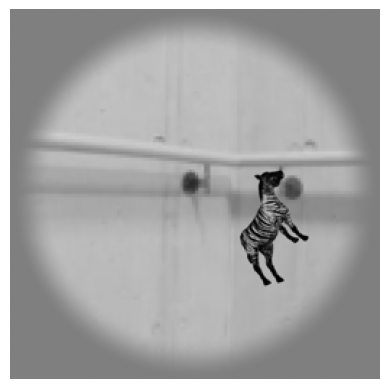

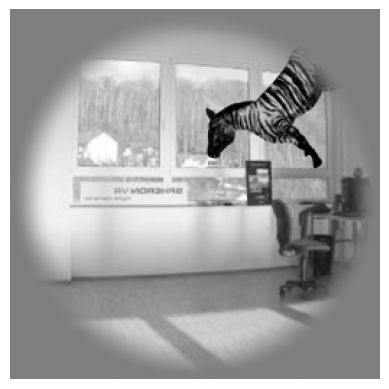

In [ ]:
from google.colab import files

for i in range(411,413):
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_rest[i], (2,1,0)))/255)
  plt.axis('off')
  plt.savefig(f"training{i}.jpg", bbox_inches='tight', transparent=True, pad_inches=0)
  files.download(f"training{i}.jpg")

In [ ]:
img_rest_indxs = np.empty(80, dtype=int)
indx = 0
start = 2
end = 0
for i in range(10):
  end = end+groups_rest[i]
  print(f"start: {start}")
  print(f"end: {end}")
  for i in range(8):
    x = np.random.randint(start, end)
    if x in img_rest_indxs:
      x = np.random.randint(start, end)
      if x in img_rest_indxs:
        x = np.random.randint(start, end)
      elif x > 461:
        x = np.random.randint(start, end)
      else:
        img_rest_indxs[indx] = x

    elif x > 461:
      x = np.random.randint(start, end)
      if x in img_rest_indxs:
        x = np.random.randint(start, end)
      elif x > 461:
        x = np.random.randint(start, end)
      else:
        img_rest_indxs[indx] = x

    else:
      img_rest_indxs[indx] = x
    indx += 1

  start = end + 2

print(img_rest_indxs)



start: 2
end: 52.0
start: 54.0
end: 88.0
start: 90.0
end: 128.0
start: 130.0
end: 177.0
start: 179.0
end: 214.0
start: 216.0
end: 271.0
start: 273.0
end: 320.0
start: 322.0
end: 372.0
start: 374.0
end: 411.0
start: 413.0
end: 461.0
[                 31                  36                  19
                   2                  49                   7
                  35                  17                  83
                  80                  71                  68
                  56                  87                  86
                  78                 113                  96
                 115                 105                 109
                 114                 111                  92
                 164                 155                 136
                 176                 134                 159
                 165                 160                 202
                 199                 189                 208
                 203                

In [ ]:
from google.colab import files

for i in range(70,80):
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_rest[img_rest_indxs[i]], (2,1,0)))/255)
  plt.axis('off')
  plt.savefig(f"{i+700}.jpg", bbox_inches='tight', transparent=True, pad_inches=0)
  files.download(f"{i+700}.jpg")


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (7 outputs left out)

<IPython.core.display.Javascript object>

IndexError: ignored

Error in callback <function flush_figures at 0x7efc7c54d940> (for post_execute):


KeyboardInterrupt: ignored

# Sampling and processing of challenge and control images

**8 images are sampled per category per difficulty, so 160 images in total**

The samples are based on smallest absolute difference to the mean and sd of the total dataset


the total control sample mean = 5.32707209082577 and std = 1.0425738884007067
[{'Abs_diff_means': 0.013251387209450627,
  'Abs_diff_stds': 0.004682113227053808,
  'Mean': 5.340323478035221,
  'STD': 1.0472560016277606,
  'Sample': array([21.,  1., 20., 27.,  8., 17., 25., 15.]),
  'object': 'bear',
  'sample number': 1019},
 {'Abs_diff_means': 0.3034554039791688,
  'Abs_diff_stds': 0.12212731080954897,
  'Mean': 5.0236166868466015,
  'STD': 0.9204465775911578,
  'Sample': array([33., 39., 48., 49., 45., 35., 40., 42.]),
  'object': 'elph',
  'sample number': 1415},
 {'Abs_diff_means': 0.005262412534013272,
  'Abs_diff_stds': 0.0015817749497373246,
  'Mean': 5.3323345033597835,
  'STD': 1.0409921134509694,
  'Sample': array([79., 60., 64., 76., 74., 67., 65., 56.]),
  'object': 'face',
  'sample number': 952},
 {'Abs_diff_means': 0.0015452485662326154,
  'Abs_diff_stds': 0.02723916589902209,
  'Mean': 5.328617339392003,
  'STD': 1.0153347225016847,
  'Sample': array([81., 94., 88., 85.,

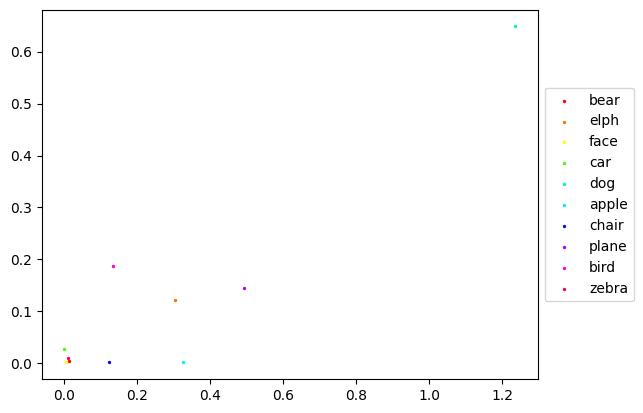

In [ ]:
 # Control Images
import pprint
import pandas as pd
from numpy import random
from scipy.stats import rankdata

# define category names
label = ['bear', 'elph', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']

# calculate total performance and the mean and standart deviation of total performance
d2_add_con = array_alex_d2_con + array_human_d2_con

mean_d2_con = np.mean(d2_add_con)
std_d2_con = np.std(d2_add_con)
print(f"the total control sample mean = {mean_d2_con} and std = {std_d2_con}")

# define arrays for the sampled data
Data_con = []
img_sample_con = []

fig = plt.figure()
ax1 = fig.add_subplot(111)

for i in range(1,11):
  data_means_con = np.empty(1500)
  data_stds_con = np.empty(1500)
  data_diff_means_con = np.empty(1500)
  data_diff_stds_con = np.empty(1500)
  data_idxs_con = np.empty((1500,8))
  for k in range(1500):
    obj_idx_con = array_obj_con == i
    img_idxs_con = np.where(obj_idx_con)[0]
    random.shuffle(img_idxs_con)

    d2_add_sample_con = d2_add_con[img_idxs_con[:8]]

    data_means_con[k] = np.mean(d2_add_sample_con)
    data_stds_con[k] = np.std(d2_add_sample_con)
    data_diff_means_con[k] = abs(mean_d2_con - (np.mean(d2_add_sample_con)))
    data_diff_stds_con[k] = abs(std_d2_con - (np.std(d2_add_sample_con)))
    data_idxs_con[k] = img_idxs_con[:8]

  sum_ranks_con = (rankdata(data_diff_means_con, method='min')) + (rankdata(data_diff_stds_con, method='min'))
  dummy_win_con = np.where((rankdata(sum_ranks_con, method='min')) == 1)
  win_con = dummy_win_con[0][0]

  Data_con.append({'object' : label[i-1],
                'sample number' : win_con,
                'Sample' : data_idxs_con[win_con],
                'Mean' : data_means_con[win_con],
                'Abs_diff_means' : data_diff_means_con[win_con],
                'STD' : data_stds_con[win_con],
                'Abs_diff_stds' : data_diff_stds_con[win_con],
              })
  img_sample_con.append(data_idxs_con[win_con])

  ax1.scatter(data_diff_means_con[win_con], data_diff_stds_con[win_con], s=2, c=color[i-1],marker="o", label=label[i-1])

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

pprint.pprint(Data_con)
print(img_sample_con)


the total challenge sample mean = 4.288307291348688 and std = 0.8161157236239953
[{'Abs_diff_means': 0.016826745364658002,
  'Abs_diff_stds': 0.004284842092186381,
  'Mean': 4.27148054598403,
  'STD': 0.8204005657161817,
  'Sample': array([16.,  1., 12.,  3.,  0., 21., 17., 23.]),
  'object': 'bear',
  'sample number': 1291},
 {'Abs_diff_means': 0.014626184680458287,
  'Abs_diff_stds': 0.006826144919865551,
  'Mean': 4.27368110666823,
  'STD': 0.8229418685438609,
  'Sample': array([38., 53., 31., 33., 46., 62., 50., 42.]),
  'object': 'elph',
  'sample number': 853},
 {'Abs_diff_means': 0.006236024430179121,
  'Abs_diff_stds': 0.0077060755517227575,
  'Mean': 4.294543315778867,
  'STD': 0.8238217991757181,
  'Sample': array([68., 69., 86., 82., 74., 77., 80., 72.]),
  'object': 'face',
  'sample number': 1228},
 {'Abs_diff_means': 0.0012806309392239257,
  'Abs_diff_stds': 0.005940838861293596,
  'Mean': 4.289587922287912,
  'STD': 0.8220565624852889,
  'Sample': array([ 90.,  92.,  94.

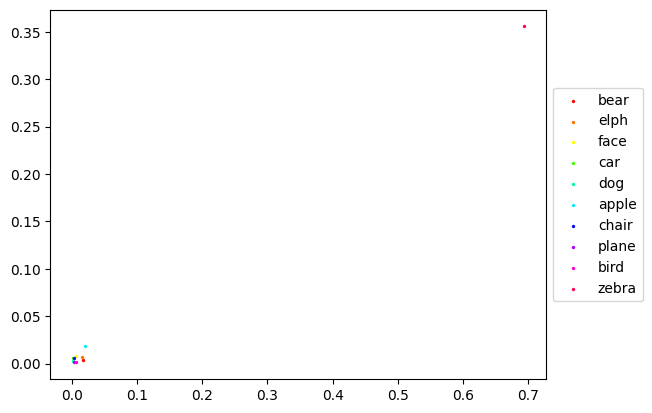

In [ ]:
# Challenge Images
d2_add_chal = array_alex_d2_chal + array_human_d2_chal

mean_d2_chal = np.mean(d2_add_chal)
std_d2_chal = np.std(d2_add_chal)
print(f"the total challenge sample mean = {mean_d2_chal} and std = {std_d2_chal}")
Data_chal = []
img_sample_chal = []

fig = plt.figure()
ax1 = fig.add_subplot(111)

for i in range(1,11):
  data_means_chal = np.empty(1500)
  data_stds_chal = np.empty(1500)
  data_diff_means_chal = np.empty(1500)
  data_diff_stds_chal = np.empty(1500)
  data_idxs_chal = np.empty((1500,8))
  for k in range(1500):
    obj_idx_chal = array_obj_chal == i
    img_idxs_chal = np.where(obj_idx_chal)[0]
    random.shuffle(img_idxs_chal)

    d2_add_sample_chal = d2_add_chal[img_idxs_chal[:8]]

    data_means_chal[k] = np.mean(d2_add_sample_chal)
    data_stds_chal[k] = np.std(d2_add_sample_chal)
    data_diff_means_chal[k] = abs(mean_d2_chal - (np.mean(d2_add_sample_chal)))
    data_diff_stds_chal[k] = abs(std_d2_chal - (np.std(d2_add_sample_chal)))
    data_idxs_chal[k] = img_idxs_chal[:8]

  sum_ranks_chal = (rankdata(data_diff_means_chal, method='min')) + (rankdata(data_diff_stds_chal, method='min'))
  dummy_win_chal = np.where((rankdata(sum_ranks_chal, method='min')) == 1)
  win_chal = dummy_win_chal[0][0]

  Data_chal.append({'object' : label[i-1],
                    'sample number' : win_chal,
                    'Sample' : data_idxs_chal[win_chal],
                    'Mean' : data_means_chal[win_chal],
                    'Abs_diff_means' : data_diff_means_chal[win_chal],
                    'STD' : data_stds_chal[win_chal],
                    'Abs_diff_stds' : data_diff_stds_chal[win_chal],
                  })
  img_sample_chal.append(data_idxs_chal[win_chal])

  ax1.scatter(data_diff_means_chal[win_chal], data_diff_stds_chal[win_chal], s=2, c=color[i-1],marker="o", label=label[i-1])

plt.legend(loc='center left', bbox_to_anchor=(1, 0.5))

pprint.pprint(Data_chal)
print(img_sample_chal)

In [ ]:
array_img_sample_chal = np.int_(img_sample_chal)
array_img_sample_con = np.int_(img_sample_con)

mean_chal = np.empty(10)
mean_con = np.empty(10)

for i in range(10):
  mean_chal[i] = np.mean(array_human_d2_chal[array_img_sample_chal[i]])
print(f"the total mean of the challenge sample = {np.mean(mean_chal)}")
print(f"per category, this is {mean_chal}")

for i in range(10):
  mean_con[i] = np.mean(array_human_d2_con[array_img_sample_con[i]])
print(f"the total mean of the control sample = {np.mean(mean_con)}")
print(f"per category, this is {mean_con}")


the total mean of the challenge sample = 3.2251648911544883
per category, this is [3.24447011 3.22906023 3.19359648 3.23120108 3.23877299 3.19002182
 3.11742738 3.1541475  3.15308187 3.49986947]
the total mean of the control sample = 2.872838528540875
per category, this is [2.84359499 2.93789016 2.85781267 3.02415024 2.45635617 3.07247642
 2.92413148 2.76612553 2.89974257 2.94610506]


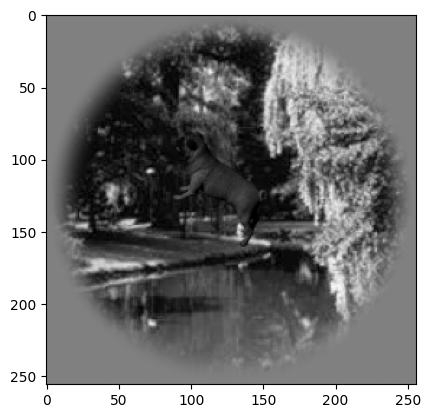

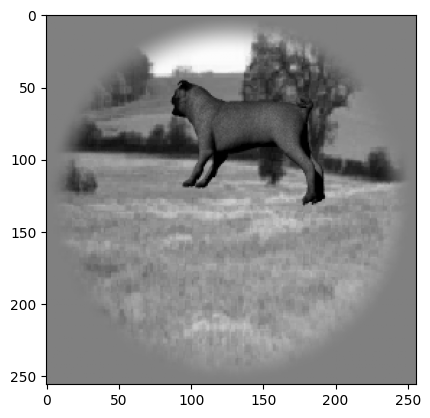

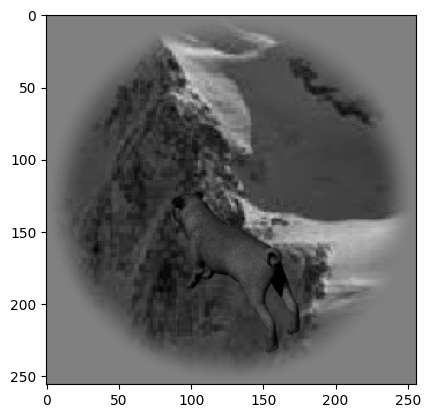

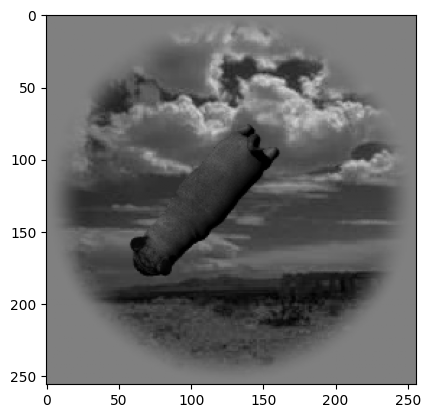

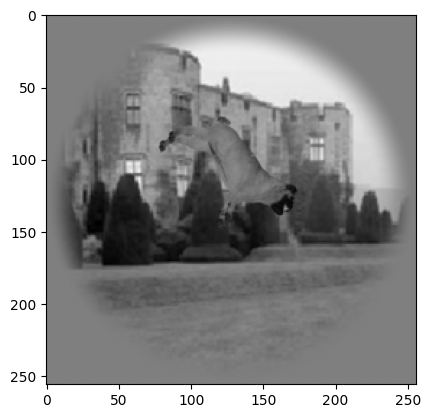

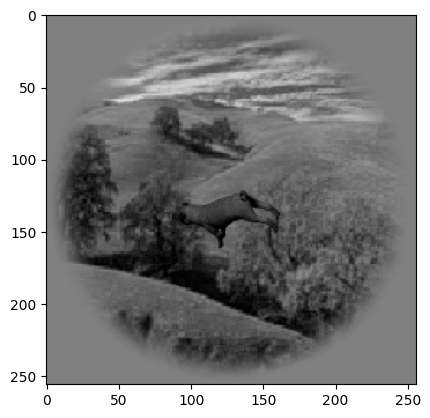

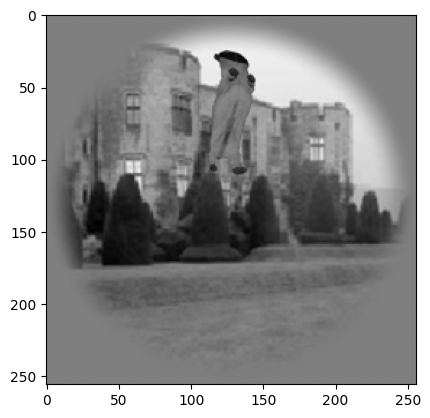

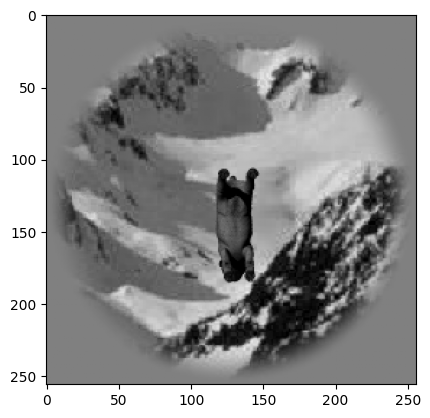

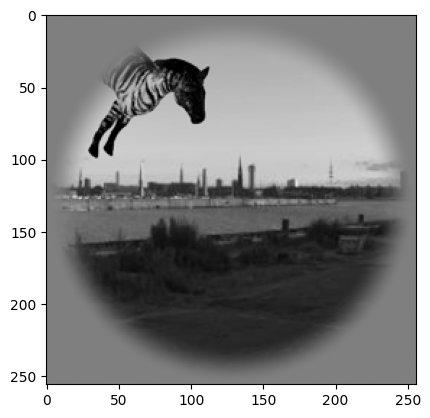

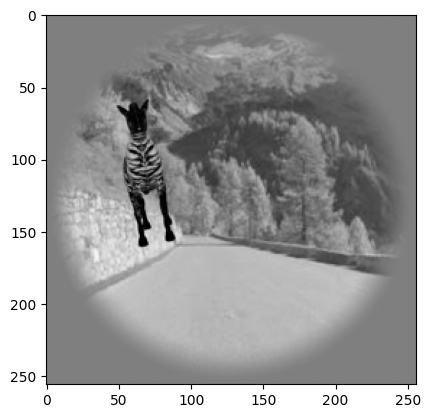

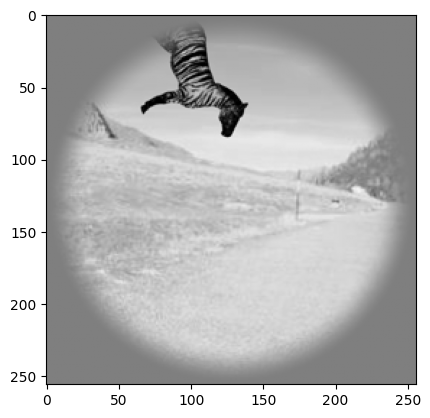

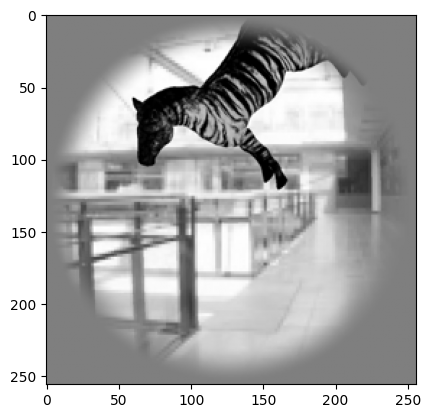

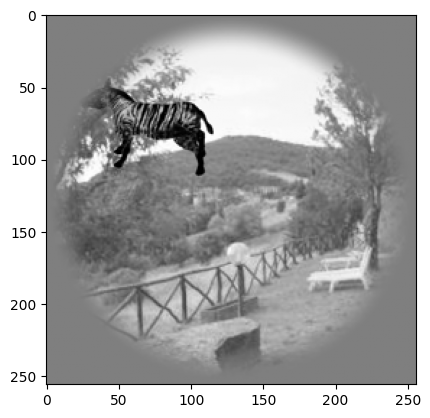

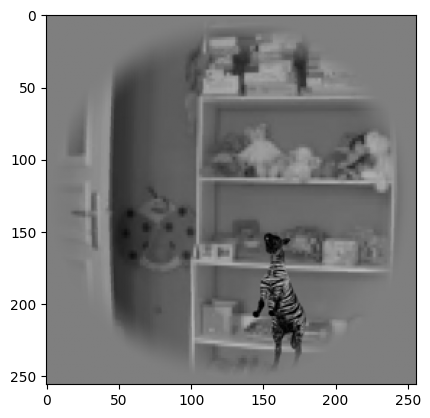

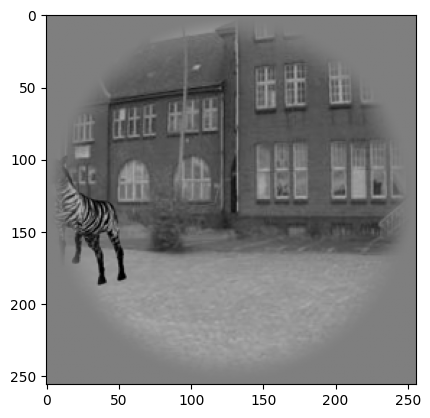

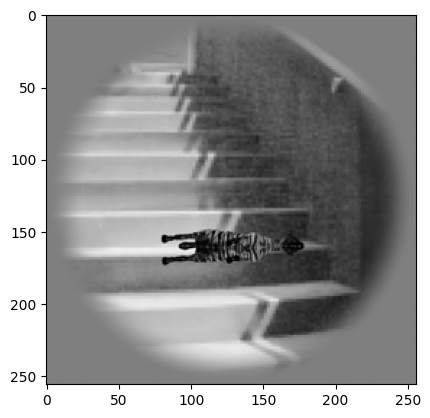

In [ ]:
# check wether images that have been sampled are the same images printed previously, so whether images have been assigned to the right condition

# arrays needed for this code snippet
array_img_sample_chal = np.int_(img_sample_chal)
array_img_sample_con = np.int_(img_sample_con)

for i in range(8):  # control dog category
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_con[array_img_sample_con[4][i]], (2,1,0)))/255)

for i in range(8):  # challenge zebra category
  fig, ax = plt.subplots()
  plt.imshow((np.transpose(img_chal[array_img_sample_chal[9][i]], (2,1,0)))/255)

# Creating one array for all stimuli and a lookup array

The stimulus array elements 0 to 79 are challenge and 80 to 159 control images, 8 images per category.

The lookup array is a 4D-array with the variables **image index, stimulus difficulty, category, stimulus duration** and **stimulus familiarity**

- Stimulus duration and familiarity are randomly asssigned to each image

In [ ]:
array_img_sample_chal = np.int_(img_sample_chal)
array_img_sample_con = np.int_(img_sample_con)

categories = ['bear', 'elephant', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']
distractor_categories = ['bear', 'elephant', 'face', 'car', 'dog', 'apple', 'chair', 'plane', 'bird', 'zebra']

randomization_idxs = (np.linspace(0,159,num=160)).astype(int)

stim_array = np.empty((160,256,256,3))
lookup_array = np.empty(160, dtype=object)

counter = -1

# Challenge images
for i in range(10):
  randomization=np.array([1,2,3,4,5,6,7,8]) # 1: Short, familiar, 2: Short, novel, 3: Long, familiar, 4: Long, novel
  random.shuffle(randomization)  # Randomize familiarity and duration per category
  for k in range(8):
    counter+=1
    random.shuffle(distractor_categories)  # randomly shuffle the distractor categories per image
    stim_array[randomization_idxs[counter],:,:,:] = np.transpose(img_chal[array_img_sample_chal[i][k]], (2,1,0))
    if randomization[k]==1:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "familiar", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "familiar", "left", distractor_categories[0]]

    if randomization[k]==2:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "novel", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "novel", "left", distractor_categories[0]]

    if randomization[k]==3:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "familiar", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "familiar", "left", distractor_categories[0]]

    if randomization[k]==4:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "novel", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "novel", "left", distractor_categories[0]]

    if randomization[k]==5:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "familiar", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "familiar", "right", distractor_categories[0]]

    if randomization[k]==6:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "novel", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "short", "novel", "right", distractor_categories[0]]

    if randomization[k]==7:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "familiar", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "familiar", "right", distractor_categories[0]]

    if randomization[k]==8:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "novel", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'challenge', categories[i], "long", "novel", "right", distractor_categories[0]]

# Control Images
for i in range(10):
  randomization=np.array([1,2,3,4,5,6,7,8])
  random.shuffle(randomization)
  for k in range(8):
    counter+=1
    random.shuffle(distractor_categories)  # randomly shuffle the distractor categories per image
    stim_array[randomization_idxs[counter],:,:,:] = np.transpose(img_con[array_img_sample_con[i][k]], (2,1,0))
    if randomization[k]==1:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "familiar", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "familiar", "left", distractor_categories[0]]

    if randomization[k]==2:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "novel", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "novel", "left", distractor_categories[0]]

    if randomization[k]==3:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "familiar", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "familiar", "left", distractor_categories[0]]

    if randomization[k]==4:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "novel", "left", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "novel", "left", distractor_categories[0]]

    if randomization[k]==5:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "familiar", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "familiar", "right", distractor_categories[0]]

    if randomization[k]==6:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "novel", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "short", "novel", "right", distractor_categories[0]]

    if randomization[k]==7:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "familiar", "right", distractor_categories[1]]
      else:
         lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "familiar", "right", distractor_categories[0]]

    if randomization[k]==8:
      if distractor_categories[0] == categories[i]:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "novel", "right", distractor_categories[1]]
      else:
        lookup_array[randomization_idxs[counter]] = [randomization_idxs[counter], 'control', categories[i], "long", "novel", "right", distractor_categories[0]]

print(lookup_array[1:10])

[list([1, 'challenge', 'bear', 'long', 'novel', 'right', 'apple'])
 list([2, 'challenge', 'bear', 'long', 'novel', 'left', 'chair'])
 list([3, 'challenge', 'bear', 'short', 'familiar', 'right', 'chair'])
 list([4, 'challenge', 'bear', 'long', 'familiar', 'left', 'plane'])
 list([5, 'challenge', 'bear', 'short', 'familiar', 'left', 'chair'])
 list([6, 'challenge', 'bear', 'short', 'novel', 'left', 'dog'])
 list([7, 'challenge', 'bear', 'long', 'familiar', 'right', 'chair'])
 list([8, 'challenge', 'elephant', 'short', 'familiar', 'left', 'zebra'])
 list([9, 'challenge', 'elephant', 'short', 'familiar', 'right', 'apple'])]


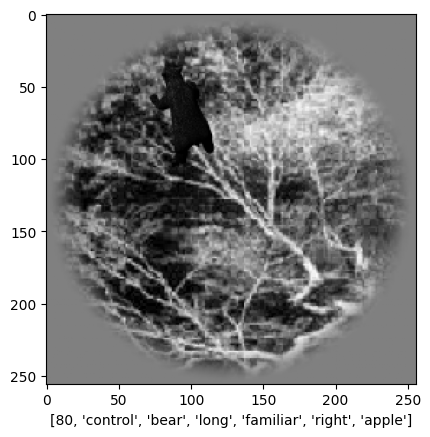

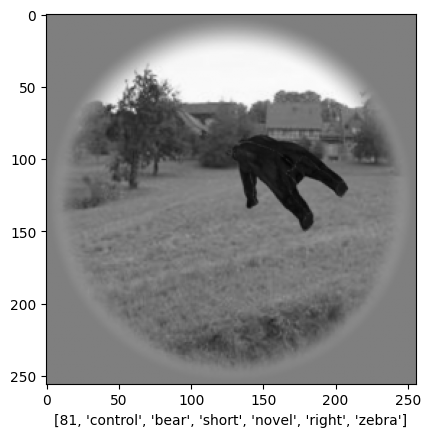

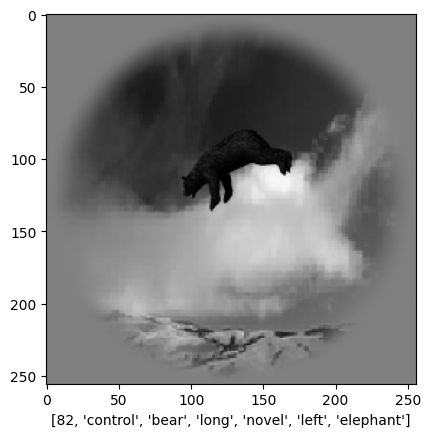

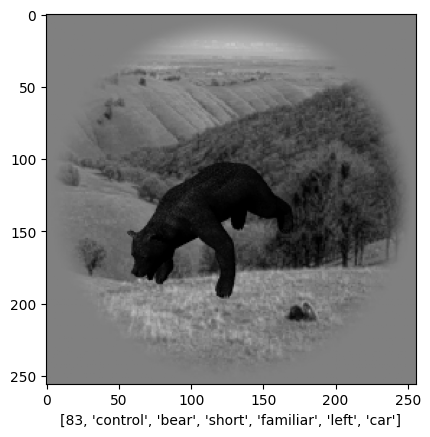

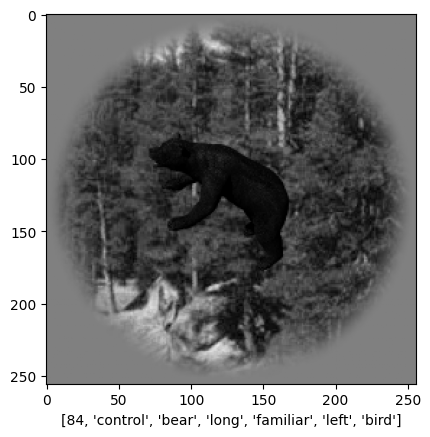

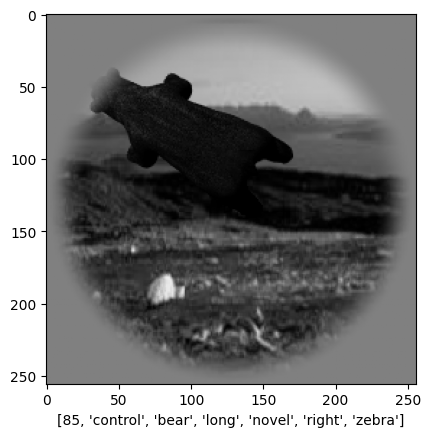

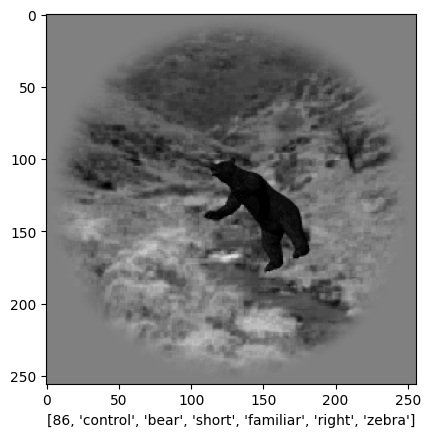

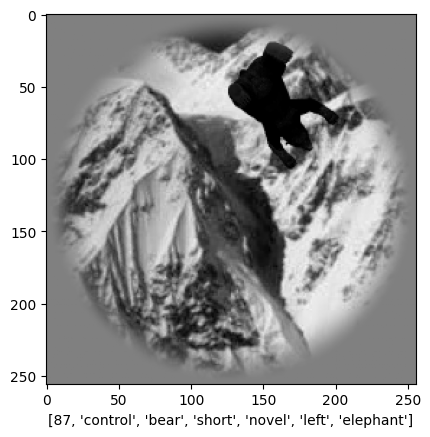

In [ ]:
from google.colab import files
for i in range(80,88):
  fig, ax = plt.subplots()
  plt.imshow(stim_array[i]/255)
  plt.xlabel(lookup_array[i])
  #plt.savefig(f"{i}.jpg", bbox_inches='tight', transparent=True, pad_inches=0)
  #files.download(f"{i}.jpg")

**Now, randomly shuffle the array 5 times in order to create 5 randomizations and save them**

In [ ]:
import pandas as pd
import csv
for i in range(1,6):
  random.shuffle(randomization_idxs)
  random_lookup=lookup_array[randomization_idxs]
  random_lookup_df = pd.DataFrame(random_lookup)
  random_lookup_df.to_csv(f'randomization{i}.csv', index=False)

# Getting the mask images

In [ ]:
from ast import Not
import numpy as np
import matplotlib.pyplot as plt
import h5py
from google.colab import drive
drive.mount('/content/gdrive')
h5path = '/content/gdrive/MyDrive/scram_array.h5'
scram_data = h5py.File(h5path, 'r')
scram_img = np.array(scram_data['scram'])

Drive already mounted at /content/gdrive; to attempt to forcibly remount, call drive.mount("/content/gdrive", force_remount=True).


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

... (10 outputs left out)

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

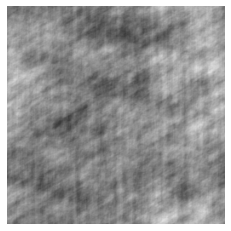

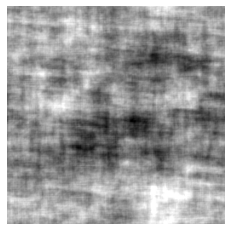

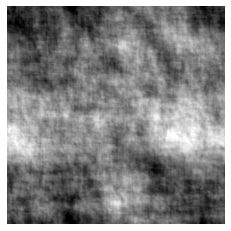

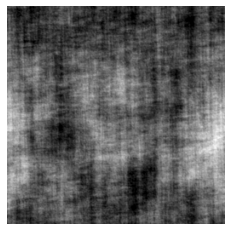

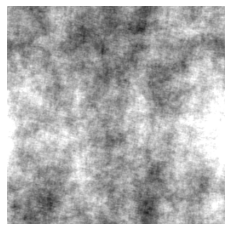

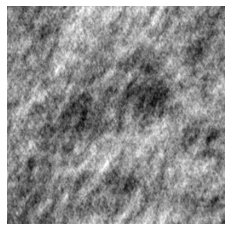

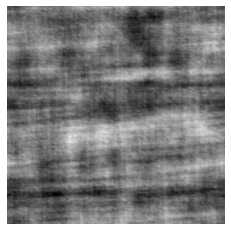

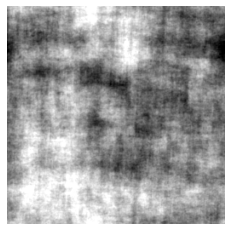

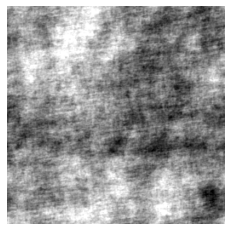

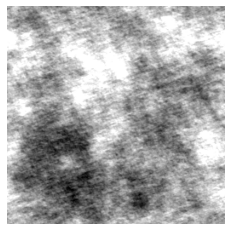

In [ ]:
from google.colab import files
for i in range(150,160):
  fig, ax = plt.subplots()
  plt.imshow(scram_img[i]/255)
  plt.axis('off')
  plt.savefig(f"mask_{i}.jpg", bbox_inches='tight', transparent=True, pad_inches=0)
  files.download(f"mask_{i}.jpg")